In [1]:
import os
os.chdir("..")       
print(os.getcwd())    

c:\college_project_Hostel_mess


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
os.makedirs("img", exist_ok=True)

In [4]:
df = pd.read_csv("dataset/mess.csv")

In [5]:
print('Average waste:', round(df.waste_pct.mean(), 1), '%')
print("Total cooked:", round(df.food_cooked_kg.sum()), 'kg')
print("Total wasted:", round(df.food_wasted_kg.sum()), 'kg')

Average waste: 45.8 %
Total cooked: 75370 kg
Total wasted: 32294 kg


In [6]:
by_meal = df.groupby("meal")["waste_pct"].mean().round(1)
by_meal = by_meal[["Breakfast", "Lunch", "Dinner"]]
print("\nWaste by meal")
print(by_meal)


Waste by meal
meal
Breakfast    60.2
Lunch        40.5
Dinner       36.6
Name: waste_pct, dtype: float64


In [7]:
by_day = df.groupby("day")["waste_pct"].mean().round(1)
by_day = by_day[["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]]
print("\nWaste by day")
print(by_day)


Waste by day
day
Monday       44.3
Tuesday      43.3
Wednesday    43.9
Thursday     43.9
Friday       44.2
Saturday     50.3
Sunday       50.5
Name: waste_pct, dtype: float64


In [8]:
normal = df[(df.is_weekend == 0) & (df.is_exam_week == 0)].waste_pct.mean()
weekend = df[df.is_weekend == 1].waste_pct.mean()
exam = df[df.is_exam_week == 1].waste_pct.mean()
print("\nNormal:", round(normal, 1), "Weekend:", round(weekend, 1), "Exam:", round(exam, 1))


Normal: 43.1 Weekend: 50.4 Exam: 50.5


In [9]:
df['waste_level']=pd.cut(df.waste_pct, bins=[0,40,50,100],
                         labels=["Low","Medium","High"])
print(df["waste_level"].value_counts())

print(df.groupby("waste_level",observed=True)[["students_present","mess_rating"]].mean().round(1))

waste_level
Low       208
High      190
Medium    142
Name: count, dtype: int64
             students_present  mess_rating
waste_level                               
Low                     330.5          3.7
Medium                  298.7          3.1
High                    208.6          3.3


In [10]:
print(df[["students_present","mess_rating","waste_pct"]].corr().round(2))

                  students_present  mess_rating  waste_pct
students_present              1.00        -0.01      -0.95
mess_rating                  -0.01         1.00      -0.25
waste_pct                    -0.95        -0.25       1.00


In [11]:
slope,intercept= np.polyfit(df.students_present,df.waste_pct,1)
print("slope:",round(slope,3))
print("Every 10 students fewer: waste rises by about", round(-slope * 10, 1), "%")

slope: -0.193
Every 10 students fewer: waste rises by about 1.9 %


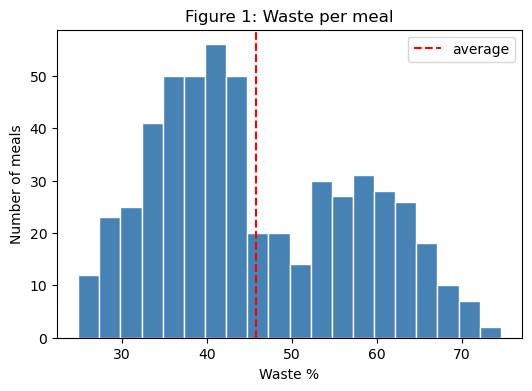

In [12]:
# --------------------------   Figure 1     -----------------------------
plt.figure(figsize=(6, 4))
plt.hist(df.waste_pct, bins=20, color="steelblue", edgecolor="white")
plt.axvline(df.waste_pct.mean(), color="red", linestyle="--", label="average")
plt.title("Figure 1: Waste per meal")
plt.xlabel("Waste %")
plt.ylabel("Number of meals")
plt.legend()
plt.savefig("img/fig1_histogram.png")
plt.show()

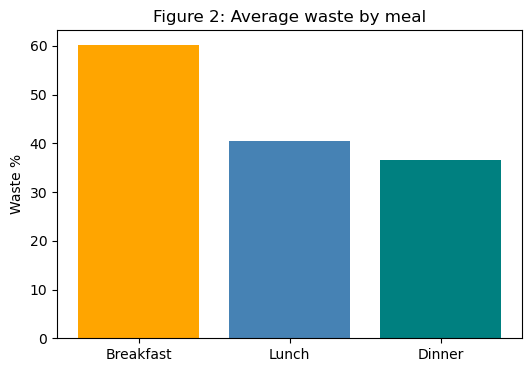

In [13]:
#----------------------------- Figure 2 -----------------------
plt.figure(figsize=(6, 4))
plt.bar(by_meal.index, by_meal.values, color=["orange", "steelblue", "teal"])
plt.title("Figure 2: Average waste by meal")
plt.ylabel("Waste %")
plt.savefig("img/fig2_meal.png")
plt.show()


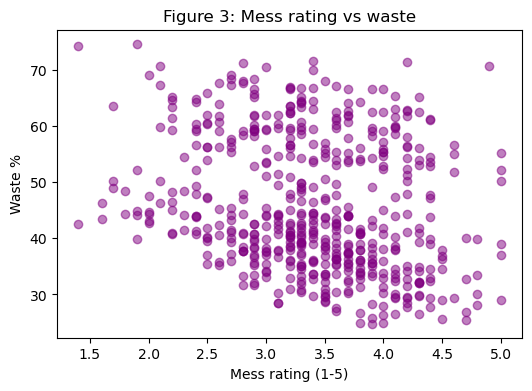

In [14]:
# ------------------------------------ Figure 3 ----------------------------------
plt.figure(figsize=(6, 4))
plt.scatter(df.mess_rating, df.waste_pct, alpha=0.5, color="purple")
plt.title("Figure 3: Mess rating vs waste")
plt.xlabel("Mess rating (1-5)")
plt.ylabel("Waste %")
plt.savefig("img/fig3_scatter.png")
plt.show()

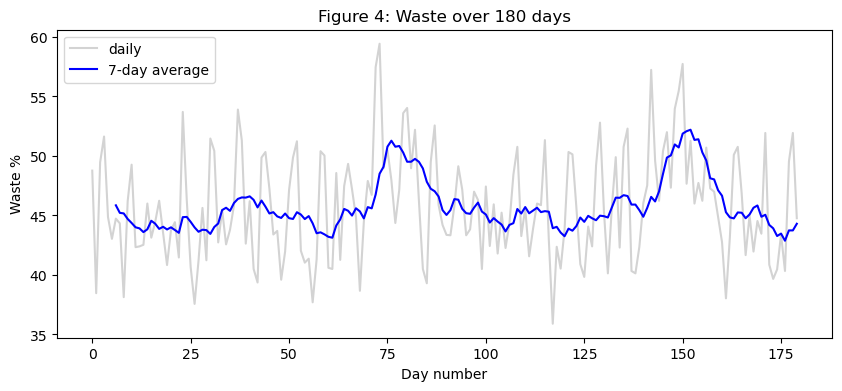

In [15]:
#---------------------------- Figure 4 -----------------------------------------
daily = df.groupby("date")["waste_pct"].mean()
plt.figure(figsize=(10, 4))
plt.plot(daily.values, color="lightgrey", label="daily")
plt.plot(daily.rolling(7).mean().values, color="blue", label="7-day average")
plt.title("Figure 4: Waste over 180 days")
plt.xlabel("Day number")
plt.ylabel("Waste %")
plt.legend()
plt.savefig("img/fig4_trend.png")
plt.show()

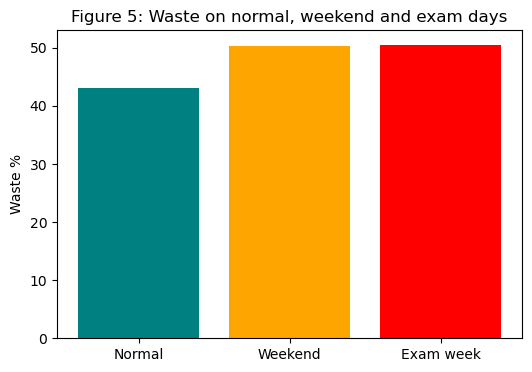

In [16]:
# ----------------------------- Figure 5 -------------------------------
plt.figure(figsize=(6, 4))
plt.bar(["Normal", "Weekend", "Exam week"], [normal, weekend, exam],
        color=["teal", "orange", "red"])
plt.title("Figure 5: Waste on normal, weekend and exam days")
plt.ylabel("Waste %")
plt.savefig("img/fig5_days.png")
plt.show()

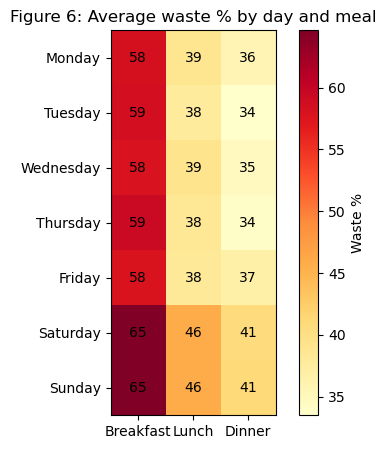

In [17]:
# --------------------------- Figure 6 (heatmap) ------------------------------
table = df.pivot_table(index="day", columns="meal", values="waste_pct", aggfunc="mean")
table = table.loc[["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
                  ["Breakfast", "Lunch", "Dinner"]]

plt.figure(figsize=(6, 5))
plt.imshow(table.values, cmap="YlOrRd")
plt.colorbar(label="Waste %")
plt.xticks(range(3), table.columns)
plt.yticks(range(7), table.index)
for i in range(7):
    for j in range(3):
        plt.text(j, i, round(table.values[i, j]), ha="center", va="center")
plt.title("Figure 6: Average waste % by day and meal")
plt.savefig("img/fig6_heatmap.png")
plt.show()

               waste    n
students_band            
<200            65.2   71
200-250         56.9  112
250-300         44.3   97
300-350         36.9  233
>350            30.6   27
             waste    n
rating_band            
<2.5          51.4   68
2.5-3.5       46.7  244
3.5-4.5       43.3  209
>4.5          41.2   19


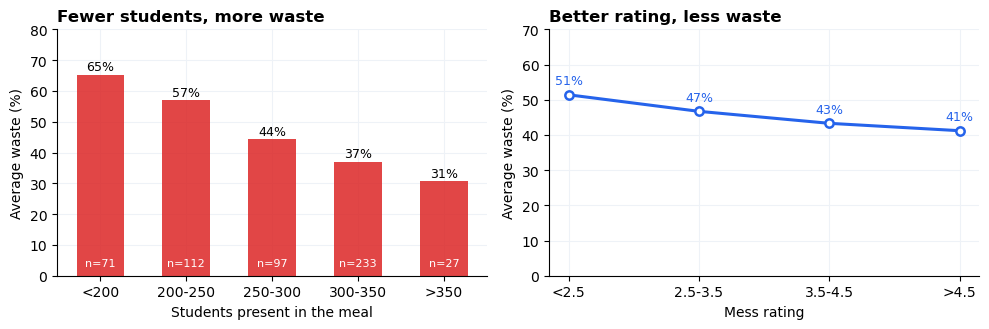

In [20]:
# Groups
df["students_band"] = pd.cut(df.students_present, bins=[0, 200, 250, 300, 350, 400],
                             labels=["<200", "200-250", "250-300", "300-350", ">350"])
df["rating_band"] = pd.cut(df.mess_rating, bins=[0, 2.5, 3.5, 4.5, 5],
                           labels=["<2.5", "2.5-3.5", "3.5-4.5", ">4.5"])


st = df.groupby("students_band", observed=True).agg(
    waste=("waste_pct", "mean"), n=("waste_pct", "size")).round(1)
rt = df.groupby("rating_band", observed=True).agg(
    waste=("waste_pct", "mean"), n=("waste_pct", "size")).round(1)
print(st)
print(rt)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))

# Left: 
axes[0].bar(st.index.astype(str), st.waste, width=0.55, color="#dc2626", alpha=0.85)
for i, (w, n) in enumerate(zip(st.waste, st.n)):
    axes[0].text(i, w + 1.5, f"{w:.0f}%", ha="center", fontsize=9)
    axes[0].text(i, 3, f"n={n}", ha="center", fontsize=8, color="white")
axes[0].set_ylim(0, 80)
axes[0].set_xlabel("Students present in the meal")
axes[0].set_ylabel("Average waste (%)")
axes[0].set_title("Fewer students, more waste", loc="left", fontweight="bold")

# Right: 
axes[1].plot(rt.index.astype(str), rt.waste.values, "o-", color="#2563eb", linewidth=2.2,
             markersize=6, markerfacecolor="white", markeredgewidth=1.8)
for i, w in enumerate(rt.waste):
    axes[1].text(i, w + 3, f"{w:.0f}%", ha="center", fontsize=9, color="#2563eb")
axes[1].set_ylim(0, 70)
axes[1].set_xlabel("Mess rating")
axes[1].set_ylabel("Average waste (%)")
axes[1].set_title("Better rating, less waste", loc="left", fontweight="bold")


for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(color="#eef2f7")
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("img/fig7_levers.png", dpi=200)
plt.show()     